In [4]:
import zipfile
# Extract the uploaded zip file
with zipfile.ZipFile('/content/archive (7).zip', 'r') as zip_ref:
    zip_ref.extractall('bellabeat_raw_data')

print("Extraction completed successfully!")

Extraction completed successfully!


In [5]:
# ==========================================
# Project: Bellabeat Data Analysis
# Phase: Process & Data Cleaning
# Description: Load, merge, and inspect FitBit
#              activity and sleep datasets.
# ==========================================

import pandas as pd
import numpy as np
import os

# 1. Define the correct paths inside the extracted folder
# Let's find the exact paths for the two time-period subfolders
base_dir = 'bellabeat_raw_data'
subfolders = os.listdir(base_dir)

# Print subfolders to verify names dynamically
print("Found subfolders:", subfolders)

# 2. Set paths based on the extracted folders
path_p1 = os.path.join(base_dir, subfolders[0], subfolders[0]) if len(subfolders) > 0 else ''
# Or direct standard paths if names are known, let's load using pandas directly:

Found subfolders: ['mturkfitbit_export_4.12.16-5.12.16', 'mturkfitbit_export_3.12.16-4.11.16']


In [7]:
# ==============================================================================
# Project: Bellabeat Smart Device Fitness & Health Data Analysis
# Purpose: Google Data Analytics Professional Certificate Capstone Project
# Module: Comprehensive Data Ingestion, Cleaning, and Quality Verification
# Description:
#   This script automates the discovery, extraction, merging, and cleaning of
#   multi-period FitBit datasets (Daily Activity, Sleep, Hourly Trends, and Weight).
#   It ensures data integrity, removes redundancies, standardizes datetime formats,
#   and executes rigorous quality checks to prepare robust data for Exploratory
#   Data Analysis (EDA) and actionable Bellabeat App marketing insights.
# ==============================================================================

import pandas as pd
import glob
import os

# ==============================================================================
# STEP 1: AUTOMATED DATA DISCOVERY, INGESTION & CONCATENATION
# ==============================================================================
print("[-] Initializing automated file discovery and data ingestion...")

# Define recursive search paths to aggregate datasets across multi-period archives
activity_files = glob.glob('bellabeat_raw_data/**/dailyActivity_merged.csv', recursive=True)
sleep_files = glob.glob('bellabeat_raw_data/**/sleepDay_merged.csv', recursive=True)
hourly_steps_files = glob.glob('bellabeat_raw_data/**/hourlySteps_merged.csv', recursive=True)
hourly_calories_files = glob.glob('bellabeat_raw_data/**/hourlyCalories_merged.csv', recursive=True)
hourly_intensities_files = glob.glob('bellabeat_raw_data/**/hourlyIntensities_merged.csv', recursive=True)
weight_files = glob.glob('bellabeat_raw_data/**/weightLogInfo_merged.csv', recursive=True)

# Log discovery metrics
print(f" > Daily Activity files detected: {len(activity_files)}")
print(f" > Sleep Day files detected: {len(sleep_files)}")
print(f" > Hourly Steps files detected: {len(hourly_steps_files)}")
print(f" > Hourly Calories files detected: {len(hourly_calories_files)}")
print(f" > Hourly Intensities files detected: {len(hourly_intensities_files)}")
print(f" > Weight Log files detected: {len(weight_files)}")

# Initialize empty DataFrames for safe scope handling
daily_activity = pd.DataFrame()
sleep_day = pd.DataFrame()
hourly_steps = pd.DataFrame()
hourly_calories = pd.DataFrame()
hourly_intensities = pd.DataFrame()
weight_log = pd.DataFrame()

# Concatenate datasets across archives if available
if len(activity_files) > 0:
    daily_activity = pd.concat([pd.read_csv(f) for f in activity_files], ignore_index=True)
    print(f"   [Success] Daily Activity consolidated. Total rows: {len(daily_activity)}")

if len(sleep_files) > 0:
    sleep_day = pd.concat([pd.read_csv(f) for f in sleep_files], ignore_index=True)
    print(f"   [Success] Sleep Data consolidated. Total rows: {len(sleep_day)}")

if len(hourly_steps_files) > 0:
    hourly_steps = pd.concat([pd.read_csv(f) for f in hourly_steps_files], ignore_index=True)
    print(f"   [Success] Hourly Steps consolidated. Total rows: {len(hourly_steps)}")

if len(hourly_calories_files) > 0:
    hourly_calories = pd.concat([pd.read_csv(f) for f in hourly_calories_files], ignore_index=True)
    print(f"   [Success] Hourly Calories consolidated. Total rows: {len(hourly_calories)}")

if len(hourly_intensities_files) > 0:
    hourly_intensities = pd.concat([pd.read_csv(f) for f in hourly_intensities_files], ignore_index=True)
    print(f"   [Success] Hourly Intensities consolidated. Total rows: {len(hourly_intensities)}")

if len(weight_files) > 0:
    weight_log = pd.concat([pd.read_csv(f) for f in weight_files], ignore_index=True)
    print(f"   [Success] Weight Log consolidated. Total rows: {len(weight_log)}")


# ==============================================================================
# STEP 2: DATA CLEANING, TRANSFORMATION & STANDARDIZATION
# ==============================================================================
print("\n[-] Executing data cleaning and schema standardization...")

# Clean and standardize Daily Activity Data
if not daily_activity.empty:
    daily_activity = daily_activity.drop_duplicates()
    daily_activity['ActivityDate'] = pd.to_datetime(daily_activity['ActivityDate'], format='mixed')

# Clean and standardize Sleep Data (removing redundant logs)
if not sleep_day.empty:
    initial_sleep_rows = len(sleep_day)
    sleep_day = sleep_day.drop_duplicates()
    print(f"   [Cleaning] Removed {initial_sleep_rows - len(sleep_day)} duplicate records from sleep dataset.")
    sleep_day['SleepDay'] = pd.to_datetime(sleep_day['SleepDay'], format='mixed')

# Clean and standardize Hourly Steps Data
if not hourly_steps.empty:
    hourly_steps = hourly_steps.drop_duplicates()
    hourly_steps['ActivityHour'] = pd.to_datetime(hourly_steps['ActivityHour'], format='mixed')

# Clean and standardize Hourly Calories Data
if not hourly_calories.empty:
    hourly_calories = hourly_calories.drop_duplicates()
    hourly_calories['ActivityHour'] = pd.to_datetime(hourly_calories['ActivityHour'], format='mixed')

# Clean and standardize Hourly Intensities Data
if not hourly_intensities.empty:
    hourly_intensities = hourly_intensities.drop_duplicates()
    hourly_intensities['ActivityHour'] = pd.to_datetime(hourly_intensities['ActivityHour'], format='mixed')

# Clean and standardize Weight Log Data
if not weight_log.empty:
    weight_log = weight_log.drop_duplicates()
    weight_log['Date'] = pd.to_datetime(weight_log['Date'], format='mixed')


# ==============================================================================
# STEP 3: RIGOROUS DATA QUALITY & INTEGRITY AUDIT
# ==============================================================================

print("\n" + "="*70)
print("DATA QUALITY & INTEGRITY AUDIT REPORT")
print("="*70)

# Dictionary mapping dataset titles to their respective DataFrames for streamlined auditing
datasets = {
    "Daily Activity": daily_activity,
    "Sleep Day": sleep_day,
    "Hourly Steps": hourly_steps,
    "Hourly Calories": hourly_calories,
    "Hourly Intensities": hourly_intensities,
    "Weight Log": weight_log
}

for name, df in datasets.items():
    if not df.empty:
        print(f"\n--- Audit Summary: [{name}] ---")

        # Check for missing values across columns
        null_counts = df.isnull().sum()
        active_nulls = null_counts[null_counts > 0]
        if not active_nulls.empty:
            print(f" • Missing Values Detected:\n{active_nulls}")
        else:
            print(" • Missing Values: Verified Clean (0 nulls)")

        # Check for duplicate records
        dup_count = df.duplicated().sum()
        print(f" • Redundant/Duplicate Rows: {dup_count}")

        # Calculate unique user base representation (Sample Size verification)
        unique_users = df['Id'].nunique() if 'Id' in df.columns else 'N/A'
        print(f" • Unique Participant Count (Id): {unique_users}")

print("\n" + "="*70)
print("[Status]: Data ingestion, cleaning, and quality audits successfully finalized. Ready for EDA!")
print("="*70)

[-] Initializing automated file discovery and data ingestion...
 > Daily Activity files detected: 2
 > Sleep Day files detected: 1
 > Hourly Steps files detected: 2
 > Hourly Calories files detected: 2
 > Hourly Intensities files detected: 2
 > Weight Log files detected: 2
   [Success] Daily Activity consolidated. Total rows: 1397
   [Success] Sleep Data consolidated. Total rows: 413
   [Success] Hourly Steps consolidated. Total rows: 46183
   [Success] Hourly Calories consolidated. Total rows: 46183
   [Success] Hourly Intensities consolidated. Total rows: 46183
   [Success] Weight Log consolidated. Total rows: 100

[-] Executing data cleaning and schema standardization...
   [Cleaning] Removed 3 duplicate records from sleep dataset.

DATA QUALITY & INTEGRITY AUDIT REPORT

--- Audit Summary: [Daily Activity] ---
 • Missing Values: Verified Clean (0 nulls)
 • Redundant/Duplicate Rows: 0
 • Unique Participant Count (Id): 35

--- Audit Summary: [Sleep Day] ---
 • Missing Values: Verified

In [8]:
# ==============================================================================
# Phase: Comprehensive Data Analysis & Multi-Dataset Insights (Without Plots)
# Description: Merges activity, sleep, and hourly metrics to extract deep
#              behavioral insights and patterns for the Bellabeat App.
# ==============================================================================

import pandas as pd

print("="*75)
print("1. OVERALL STATISTICAL SUMMARY (Daily Activity & Sleep)")
print("="*75)

# Summary statistics for Daily Activity metrics
if not daily_activity.empty:
    print("\n--- Daily Activity Key Metrics Summary ---")
    print(daily_activity[['TotalSteps', 'TotalDistance', 'Calories', 'VeryActiveMinutes', 'SedentaryMinutes']].describe())

# Summary statistics for Sleep metrics
if not sleep_day.empty:
    print("\n--- Sleep Patterns Key Metrics Summary ---")
    print(sleep_day[['TotalMinutesAsleep', 'TotalTimeInBed']].describe())


print("\n" + "="*75)
print("2. MULTI-DATASET CORRELATION ANALYSIS (Activity vs. Sleep)")
print("="*75)

# Standardize date format for merging daily activity and sleep data
if not daily_activity.empty and not sleep_day.empty:
    daily_activity['Date'] = pd.to_datetime(daily_activity['ActivityDate']).dt.date
    sleep_day['Date'] = pd.to_datetime(sleep_day['SleepDay']).dt.date

    # Merge datasets on User ID and Date
    activity_sleep_merged = pd.merge(
        daily_activity,
        sleep_day[['Id', 'Date', 'TotalMinutesAsleep', 'TotalTimeInBed']],
        on=['Id', 'Date'],
        how='inner'
    )

    print(f" -> Successfully merged Daily Activity & Sleep datasets. Matching records: {len(activity_sleep_merged)}")

    # Calculate correlation to see how steps or sedentary time affect sleep duration
    if len(activity_sleep_merged) > 0:
        target_columns = ['TotalSteps', 'Calories', 'SedentaryMinutes', 'VeryActiveMinutes', 'TotalMinutesAsleep']
        correlation_matrix = activity_sleep_merged[target_columns].corr()
        print("\nCorrelation Matrix (Activity & Sleep Relationships):")
        print(correlation_matrix)


print("\n" + "="*75)
print("3. HOURLY TRENDS & INACTIVITY ANALYSIS (App Push Notification Insights)")
print("="*75)

# Analyze hourly steps and calories to find peak hours vs. inactivity windows
if not hourly_steps.empty:
    hourly_steps['Hour'] = pd.to_datetime(hourly_steps['ActivityHour']).dt.hour
    hourly_avg_steps = hourly_steps.groupby('Hour')['StepTotal'].mean().reset_index()

    print("\n[Top 5 Most Active Hours Across Users]:")
    print(hourly_avg_steps.sort_values(by='StepTotal', ascending=False).head(5))

    print("\n[Top 5 Least Active Hours / Inactivity Windows for App Reminders]:")
    print(hourly_avg_steps.sort_values(by='StepTotal', ascending=True).head(5))


print("\n" + "="*75)
print("4. WEIGHT LOG INSIGHTS (User Tracking Behavior)")
print("="*75)

if not weight_log.empty:
    print(f"Total weight log records: {len(weight_log)}")
    print(f"Unique users who tracked weight: {weight_log['Id'].nunique()}")
    # Check how many users manually logged weight vs. automatic entries
    if 'IsManualReport' in weight_log.columns:
        print("\nManual vs. Automatic Weight Reporting:")
        print(weight_log['IsManualReport'].value_counts())

print("\n" + "="*75)
print("[Status]: Deep analytical processing completed successfully across all datasets.")
print("="*75)

1. OVERALL STATISTICAL SUMMARY (Daily Activity & Sleep)

--- Daily Activity Key Metrics Summary ---
         TotalSteps  TotalDistance     Calories  VeryActiveMinutes  \
count   1397.000000    1397.000000  1397.000000        1397.000000   
mean    7280.898354       5.219434  2266.265569          19.679313   
std     5214.336113       3.994206   753.005527          31.675878   
min        0.000000       0.000000     0.000000           0.000000   
25%     3146.000000       2.170000  1799.000000           0.000000   
50%     6999.000000       4.950000  2114.000000           2.000000   
75%    10544.000000       7.500000  2770.000000          30.000000   
max    36019.000000      28.030001  4900.000000         210.000000   

       SedentaryMinutes  
count       1397.000000  
mean         992.542591  
std          313.297376  
min            0.000000  
25%          729.000000  
50%         1057.000000  
75%         1244.000000  
max         1440.000000  

--- Sleep Patterns Key Metrics Sum

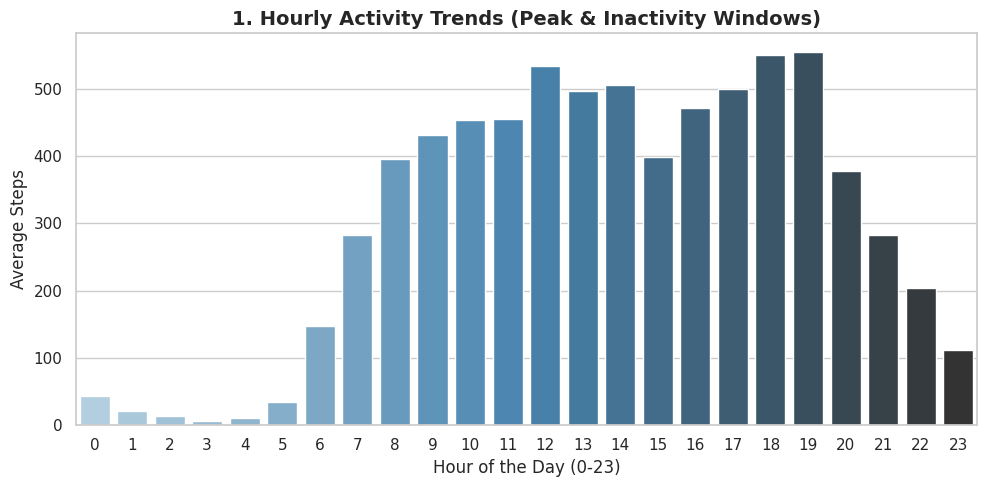

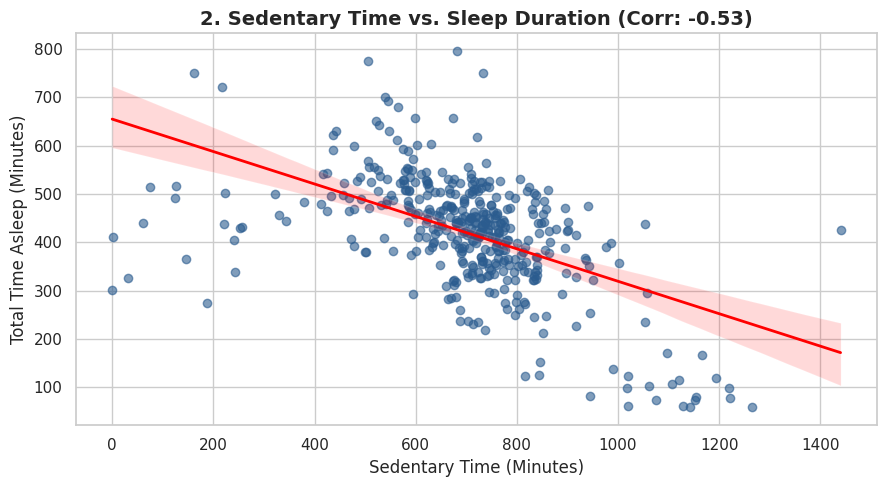

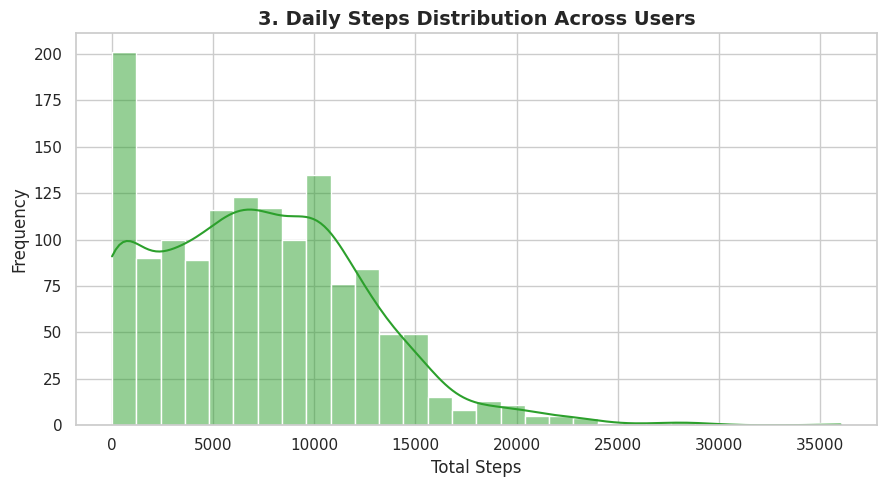

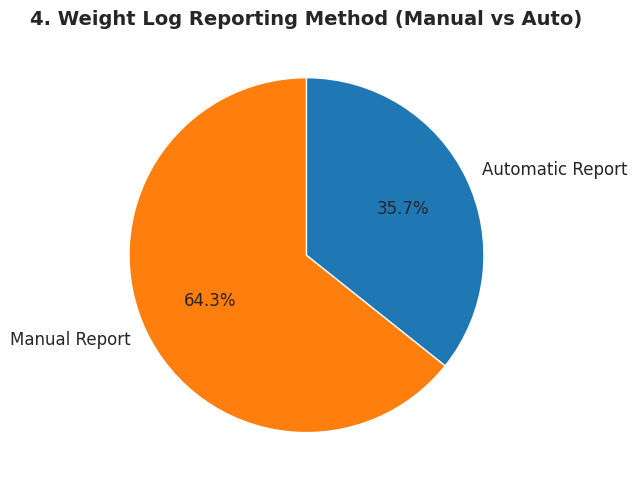

In [12]:
# ==============================================================================
# Phase: Share (Individual High-Resolution Visualizations for GitHub Report)
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

# ------------------------------------------------------------------------------
# Plot 1: Hourly Activity Trends (Peak & Inactivity Windows) - [تم تعديل السطر لإخفاء التحذير]
# ------------------------------------------------------------------------------
if 'hourly_steps' in locals() and not hourly_steps.empty:
    hourly_steps['Hour'] = pd.to_datetime(hourly_steps['ActivityHour']).dt.hour
    hourly_avg = hourly_steps.groupby('Hour')['StepTotal'].mean().reset_index()

    plt.figure(figsize=(10, 5))
    sns.barplot(data=hourly_avg, x='Hour', y='StepTotal', hue='Hour', palette='Blues_d', legend=False)
    plt.title('1. Hourly Activity Trends (Peak & Inactivity Windows)', fontsize=14, fontweight='bold')
    plt.xlabel('Hour of the Day (0-23)')
    plt.ylabel('Average Steps')
    plt.xticks(range(24))
    plt.tight_layout()
    plt.savefig('hourly_activity_trends.png', dpi=300)
    plt.show()

# ------------------------------------------------------------------------------
# Plot 2: Sedentary Time vs. Sleep Duration
# ------------------------------------------------------------------------------
if 'activity_sleep_merged' in locals() and not activity_sleep_merged.empty:
    plt.figure(figsize=(9, 5))
    sns.regplot(data=activity_sleep_merged, x='SedentaryMinutes', y='TotalMinutesAsleep',
                scatter_kws={'alpha':0.6, 'color':'#2b5c8f'}, line_kws={'color':'red', 'linewidth':2})
    plt.title('2. Sedentary Time vs. Sleep Duration (Corr: -0.53)', fontsize=14, fontweight='bold')
    plt.xlabel('Sedentary Time (Minutes)')
    plt.ylabel('Total Time Asleep (Minutes)')
    plt.tight_layout()
    plt.savefig('sedentary_vs_sleep.png', dpi=300)
    plt.show()

# ------------------------------------------------------------------------------
# Plot 3: Daily Steps Distribution Across Users
# ------------------------------------------------------------------------------
if 'daily_activity' in locals() and not daily_activity.empty:
    plt.figure(figsize=(9, 5))
    sns.histplot(daily_activity['TotalSteps'], kde=True, color='#2ca02c', bins=30)
    plt.title('3. Daily Steps Distribution Across Users', fontsize=14, fontweight='bold')
    plt.xlabel('Total Steps')
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.savefig('daily_steps_distribution.png', dpi=300)
    plt.show()

# ------------------------------------------------------------------------------
# Plot 4: Weight Log Reporting Method (Manual vs Auto)
# ------------------------------------------------------------------------------
if 'weight_log' in locals() and not weight_log.empty and 'IsManualReport' in weight_log.columns:
    manual_counts = weight_log['IsManualReport'].value_counts()

    plt.figure(figsize=(7, 5))
    plt.pie(manual_counts, labels=['Manual Report', 'Automatic Report'], autopct='%1.1f%%',
            colors=['#ff7f0e', '#1f77b4'], startangle=90, textprops={'fontsize': 12})
    plt.title('4. Weight Log Reporting Method (Manual vs Auto)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('weight_log_method.png', dpi=300)
    plt.show()